In [26]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt
 
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)

In [27]:
# Реализуйте высокочастотную фильтрацию на основе ядра Гаусса
# Реализуйте вычисление свертки с помощью преобразования Фурье
# Реализуйте удаление периодического шума с помощью преобразования Фурье

In [28]:
# Высокочастотная фильтрация на основе ядра Гаусса
rows, cols = img.shape
dft_hp = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift_hp = np.fft.fftshift(dft_hp)

x, y = np.meshgrid(np.arange(0, cols, 1), np.arange(0, rows, 1))
sigma = 30
gauss = np.exp(-((x - (cols // 2))**2 + (y - (rows // 2))**2) / (2 * sigma**2))
mask_hp = 1 - gauss

dft_shift_filtered_hp = dft_shift_hp * mask_hp[:, :, np.newaxis]
f_ishift_hp = np.fft.ifftshift(dft_shift_filtered_hp)
img_idft_hp = cv.idft(f_ishift_hp)
img_idft_hp = cv.magnitude(img_idft_hp[:, :, 0], img_idft_hp[:, :, 1])

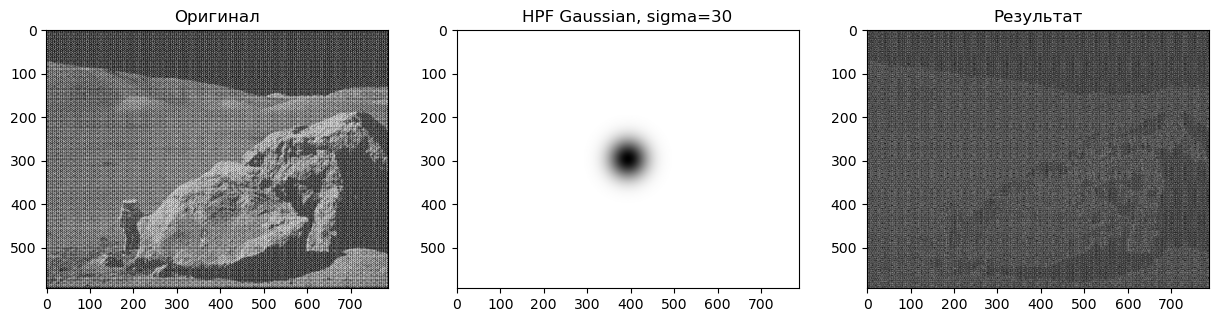

In [29]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img, cmap='gray')
ax[0].set_title('Оригинал')
ax[1].imshow(mask_hp, cmap='gray')
ax[1].set_title(f'HPF Gaussian, sigma={sigma}')
ax[2].imshow(img_idft_hp, cmap='gray')
ax[2].set_title('Результат')
plt.show()

In [30]:
# Вычисление свертки с помощью преобразования Фурье
kernel = cv.getGaussianKernel(9, 2)
kernel = np.outer(kernel, kernel).astype(np.float32)
kh, kw = kernel.shape

pad_rows, pad_cols = rows + kh - 1, cols + kw - 1
img_padded = np.pad(img, ((0, pad_rows - rows), (0, pad_cols - cols))).astype(np.float32)
kernel_padded = np.pad(kernel, ((0, pad_rows - kh), (0, pad_cols - kw))).astype(np.float32)

dft_img = cv.dft(img_padded, flags=cv.DFT_COMPLEX_OUTPUT)
dft_kernel = cv.dft(kernel_padded, flags=cv.DFT_COMPLEX_OUTPUT)
dft_conv = cv.mulSpectrums(dft_img, dft_kernel, 0)

img_back_conv = cv.idft(dft_conv)
img_back_conv = cv.magnitude(img_back_conv[:, :, 0], img_back_conv[:, :, 1])
img_conv = img_back_conv[kh//2 : kh//2 + rows, kw//2 : kw//2 + cols]

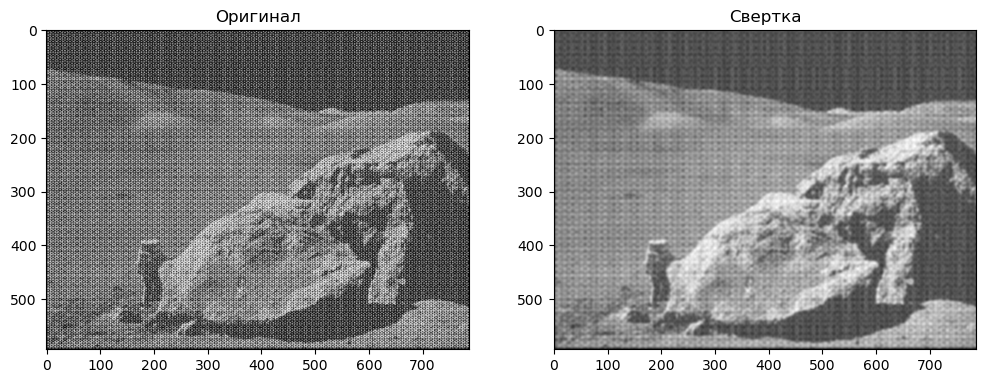

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(img, cmap='gray')
ax[0].set_title('Оригинал')
ax[1].imshow(img_conv, cmap='gray')
ax[1].set_title('Свертка')
plt.show()

In [32]:
# Удаление периодического шума с помощью преобразования Фурье
dft_noise = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift_noise = np.fft.fftshift(dft_noise)

magnitude_noise = 20 * np.log1p(cv.magnitude(dft_shift_noise[:, :, 0], dft_shift_noise[:, :, 1]))
threshold_noise = np.percentile(magnitude_noise, 99.5)
ret, peaks_noise = cv.threshold(magnitude_noise, threshold_noise, 255, cv.THRESH_BINARY)
peaks_noise = peaks_noise.astype(np.uint8)

mask_noise = 1.0 - (peaks_noise > 0).astype(np.float32)
y, x = np.ogrid[:rows, :cols]
mask_noise[(x - cols//2)**2 + (y - rows//2)**2 <= 30**2] = 1

dft_filtered_noise = dft_shift_noise * mask_noise[:, :, np.newaxis]
img_back_noise = cv.idft(np.fft.ifftshift(dft_filtered_noise))
img_clean = cv.magnitude(img_back_noise[:, :, 0], img_back_noise[:, :, 1])

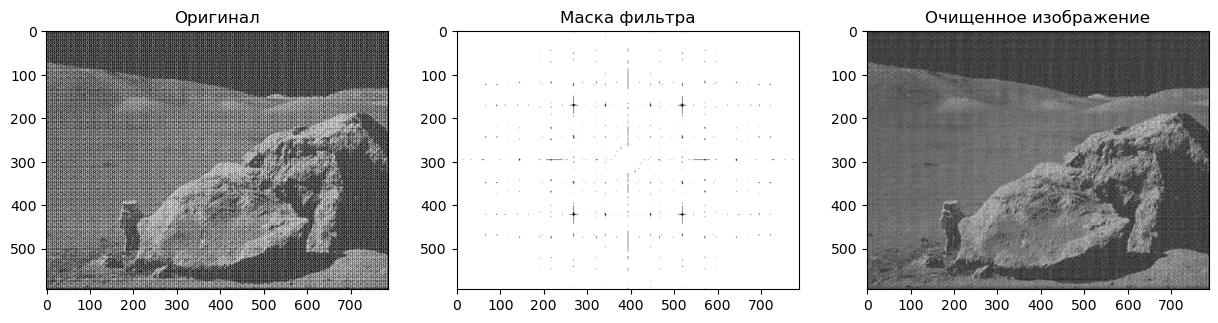

In [33]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img, cmap='gray')
ax[0].set_title('Оригинал')
ax[1].imshow(mask_noise, cmap='gray')
ax[1].set_title('Маска фильтра')
ax[2].imshow(img_clean, cmap='gray')
ax[2].set_title('Очищенное изображение')
plt.show()